In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

In [10]:
df = yf.download("^GSPC", start="2000-01-01")
df.head(10)

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC
Date,,,,,
2000-01-03,1455.219971,1478.000000,1438.359985,1469.250000,931800000
2000-01-04,1399.420044,1455.219971,1397.430054,1455.219971,1009000000
2000-01-05,1402.109985,1413.270020,1377.680054,1399.420044,1085500000
2000-01-06,1403.449951,1411.900024,1392.099976,1402.109985,1092300000
2000-01-07,1441.469971,1441.469971,1400.729980,1403.449951,1225200000
2000-01-10,1457.599976,1464.359985,1441.469971,1441.469971,1064800000
2000-01-11,1438.560059,1458.660034,1434.420044,1457.599976,1014000000
2000-01-12,1432.250000,1442.599976,1427.079956,1438.560059,974600000


In [14]:
prices = df[("Close", "^GSPC")]
print(prices)


Date
2000-01-03    1455.219971
2000-01-04    1399.420044
2000-01-05    1402.109985
2000-01-06    1403.449951
2000-01-07    1441.469971
                 ...     
2026-11-03    7568.919922
2026-11-04    7688.620117
2026-11-05    7353.729980
2026-11-06    7376.859863
2026-11-09    7544.200195
Name: (Close, ^GSPC), Length: 6754, dtype: float64


In [19]:
prices.pct_change()

Date
2000-01-03         NaN
2000-01-04   -0.038345
2000-01-05    0.001922
2000-01-06    0.000956
2000-01-07    0.027090
                ...   
2026-11-03    0.003649
2026-11-04    0.015815
2026-11-05   -0.043557
2026-11-06    0.003145
2026-11-09    0.022684
Name: (Close, ^GSPC), Length: 6754, dtype: float64

In [28]:
r_log = np.log(prices / prices.shift(1))
r_log = r_log.dropna()
R_t = prices / prices.shift(1) - 1
R_t = R_t.dropna()
R_t


Date
2000-01-04   -0.038345
2000-01-05    0.001922
2000-01-06    0.000956
2000-01-07    0.027090
2000-01-10    0.011190
                ...   
2026-11-03    0.003649
2026-11-04    0.015815
2026-11-05   -0.043557
2026-11-06    0.003145
2026-11-09    0.022684
Name: (Close, ^GSPC), Length: 6753, dtype: float64

In [29]:
prices.pct_change().dropna()

Date
2000-01-04   -0.038345
2000-01-05    0.001922
2000-01-06    0.000956
2000-01-07    0.027090
2000-01-10    0.011190
                ...   
2026-11-03    0.003649
2026-11-04    0.015815
2026-11-05   -0.043557
2026-11-06    0.003145
2026-11-09    0.022684
Name: (Close, ^GSPC), Length: 6753, dtype: float64

2020-03-16 00:00:00
0.007811645068882989


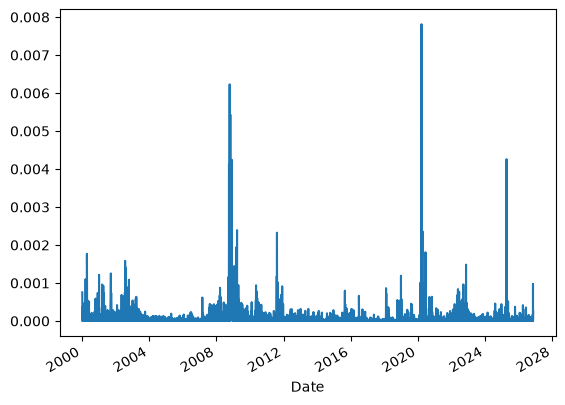

In [ ]:
diff = R_t - r_log
diff.plot()
print(diff.idxmax())
print(diff.max())


Text(0, 0.5, 'log return')

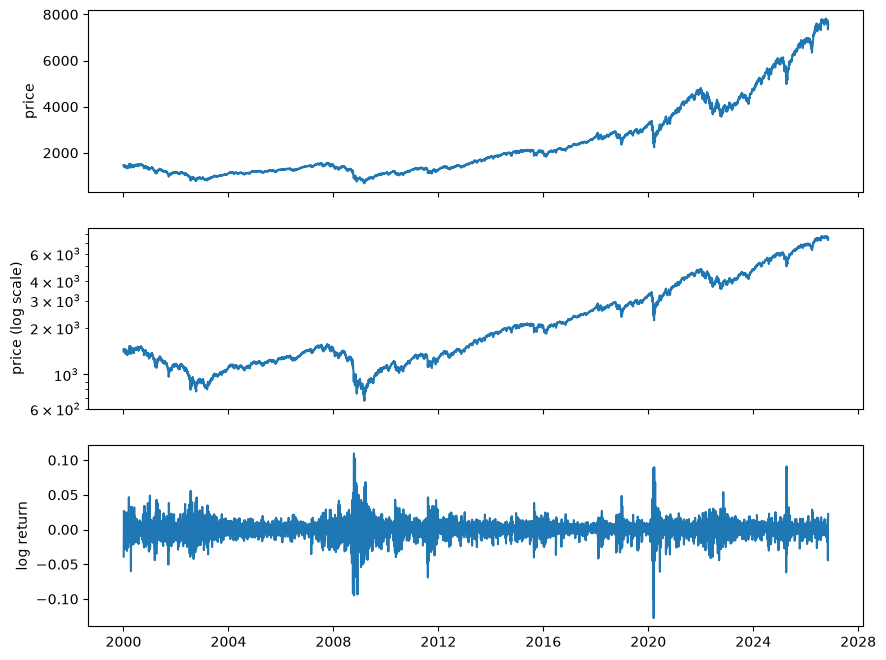

In [55]:
fig, ax = plt.subplots(3, 1, sharex=True, figsize=(10, 8))
ax[0].plot(prices, label="prices")
ax[0].set_ylabel("price")
ax[1].plot(prices)
ax[1].set_yscale("log")
ax[1].set_ylabel("price (log scale)")
ax[2].plot(r_log, label="log returns")
ax[2].set_ylabel("log return")

In [65]:
t = (prices.index - prices.index[0]).days
years = t / 365.25


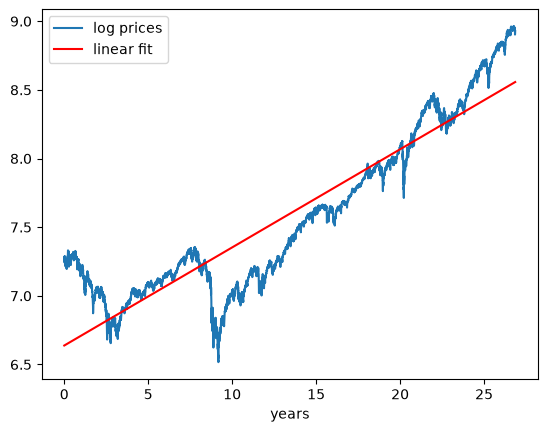

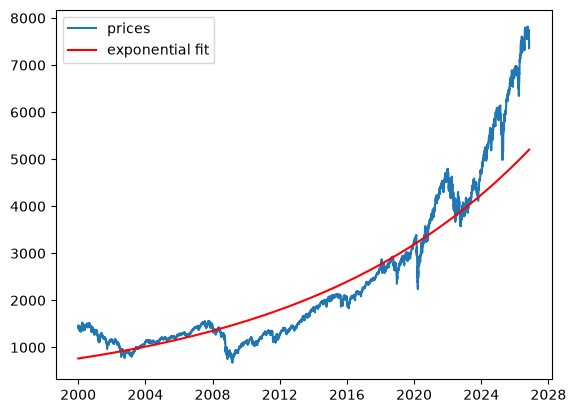

In [75]:
lin = np.polyfit(years, np.log(prices), 1)
fig, ax = plt.subplots()
ax.plot(years, np.log(prices), label="log prices")
ax.plot(years, lin[0] * years + lin[1], label="linear fit", color="red")
ax.set_xlabel("years")
ax.legend()
exp_prices = np.exp(lin[0] * years + lin[1])
fig, ax = plt.subplots()
ax.plot(prices.index, prices, label="prices")
ax.plot(prices.index, exp_prices, label="exponential fit", color="red")
ax.legend()

